# Australian Gas Export Forecast (2025–2029)

**Goal:** forecast the value of Australia's natural gas exports for 2025–2029 and test how reliable that forecast is.

**Data:** Australian Bureau of Statistics (ABS) international merchandise trade, annual values in $ millions, 1988–2024, for the three mineral fuel groups: coal (SITC 32), petroleum (SITC 33) and gas (SITC 34).

**Approach:** Holt's linear exponential smoothing in Python, compared with the Tableau exponential smoothing forecast from the original dashboard, plus a backtest to check how a model like this would have performed in the past.

## 1. Setup and data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from statsmodels.tsa.holtwinters import Holt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("abs_mineral_fuel_trade.csv")
exports = df[df["Flow"] == "Export"].set_index("Year")
imports = df[df["Flow"] == "Import"].set_index("Year")
exports.tail()

,Flow,Coal,Petroleum,Gas,Mineral_fuels_total
Year,,,,,
2020,Export,43367,7755,37699,88821
2021,Export,63504,11715,51179,126395
2022,Export,142345,17341,91648,251334
2023,Export,103331,15760,76456,195549
2024,Export,85981,15733,69718,171431


## 2. Australia's fuel trade in 2024

In [2]:
summary = pd.DataFrame({
    "Exports ($B)": exports.loc[2024, ["Coal", "Petroleum", "Gas"]] / 1000,
    "Imports ($B)": imports.loc[2024, ["Coal", "Petroleum", "Gas"]] / 1000,
})
summary["Net ($B)"] = summary["Exports ($B)"] - summary["Imports ($B)"]
summary.round(1)

,Exports ($B),Imports ($B),Net ($B)
Coal,86.0,0.3,85.7
Petroleum,15.7,56.2,-40.5
Gas,69.7,0.3,69.4


Coal is still the largest fuel export, with gas second. Petroleum looks very different: exports are small, but imports are large, so Australia is a major **net importer** of petroleum.

## 3. Gas exports over time

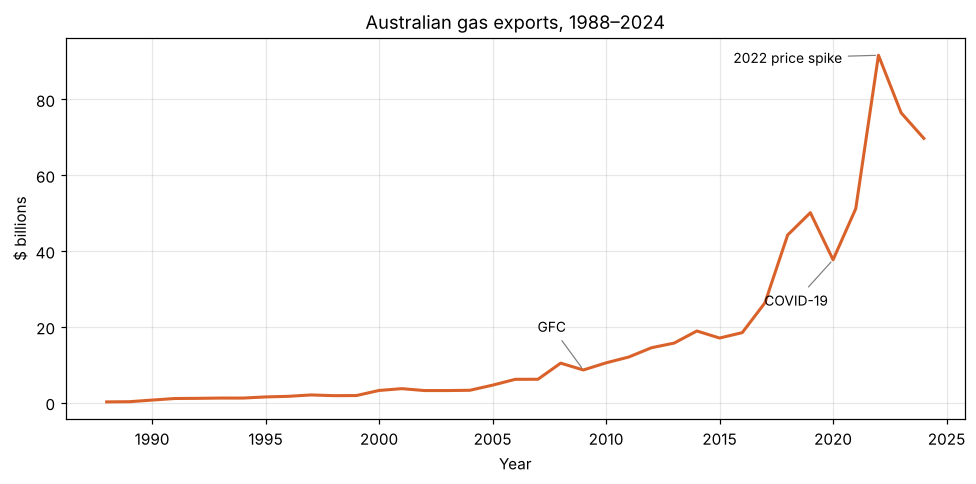

2015: $17.1B | 2022 peak: $91.6B | 2024: $69.7B


In [3]:
gas = exports["Gas"].astype(float)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(gas.index, gas / 1000, color="#d9622b", lw=2)
for year, label, dx, dy in [(2009, "GFC", -30, 25), (2020, "COVID-19", -45, -30), (2022, "2022 price spike", -95, -5)]:
    ax.annotate(label, (year, gas[year] / 1000), xytext=(dx, dy), textcoords="offset points",
                fontsize=9, arrowprops=dict(arrowstyle="-", color="grey", lw=0.8))
ax.set(title="Australian gas exports, 1988–2024", xlabel="Year", ylabel="$ billions")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("gas_exports_history.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"2015: ${gas[2015]/1000:.1f}B | 2022 peak: ${gas[2022]/1000:.1f}B | 2024: ${gas[2024]/1000:.1f}B")

Gas exports grew about fourfold between 2015 and 2024 as new LNG projects came online. The 2022 jump was mainly a **price** effect after the energy crisis, and exports have fallen in both years since.

## 4. Holt's linear forecast (trained on 2015–2024)

In [4]:
train = gas.loc[2015:2024]
holt = Holt(train.values, initialization_method="estimated").fit()
holt_fc = holt.forecast(5)

print(f"alpha (level) = {holt.params['smoothing_level']:.2f}, beta (trend) = {holt.params['smoothing_trend']:.2f}")

alpha (level) = 0.00, beta (trend) = 0.00


Both smoothing parameters come out at about zero. That means the model isn't adapting to recent years: it effectively fits a **straight trend line** through 2015–2024, so the post-2022 decline barely affects it.

## 5. Comparison with the Tableau forecast

In [5]:
years = np.arange(2025, 2030)
tableau_fc = np.array([83723, 89575, 95425, 101278, 107130])  # Tableau exponential smoothing (from the dashboard)

comparison = pd.DataFrame({
    "Year": years,
    "Holt (Python) $B": holt_fc / 1000,
    "Tableau $B": tableau_fc / 1000,
}).round(1)
comparison["Difference $B"] = (comparison["Holt (Python) $B"] - comparison["Tableau $B"]).round(1)
print(comparison.to_string(index=False))

 Year  Holt (Python) $B  Tableau $B  Difference $B
 2025              88.8        83.7            5.1
 2026              96.1        89.6            6.5
 2027             103.5        95.4            8.1
 2028             110.9       101.3            9.6
 2029             118.2       107.1           11.1


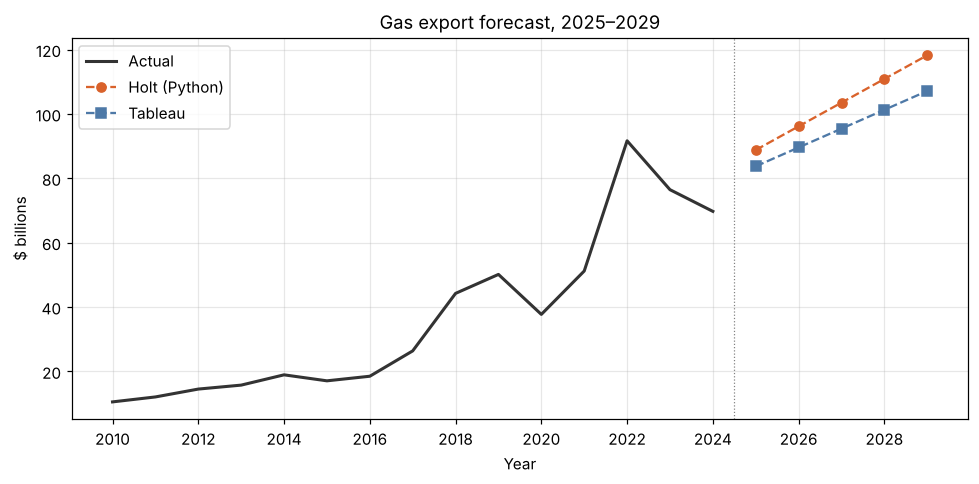

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(gas.loc[2010:].index, gas.loc[2010:] / 1000, color="#333333", lw=2, label="Actual")
ax.plot(years, holt_fc / 1000, "o--", color="#d9622b", label="Holt (Python)")
ax.plot(years, tableau_fc / 1000, "s--", color="#4e79a7", label="Tableau")
ax.axvline(2024.5, color="grey", lw=0.8, ls=":")
ax.set(title="Gas export forecast, 2025–2029", xlabel="Year", ylabel="$ billions")
ax.set_xticks(range(2010, 2030, 2))
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("gas_forecast_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Both models expect growth, with Holt higher than Tableau in every year. But both forecasts **start well above the 2024 actual** ($69.7B) even though exports fell in 2023 and 2024. The upward trend comes from the 2015–2022 boom and the 2022 price spike.

## 6. Backtest: would this approach have worked before?

To test reliability, the same method is trained on 2010–2019 only and used to predict 2020–2024, which can then be compared with what actually happened.

In [7]:
bt_train = gas.loc[2010:2019]
bt_model = Holt(bt_train.values, initialization_method="estimated").fit()
bt_pred = bt_model.forecast(5)
bt_actual = gas.loc[2020:2024].values

backtest = pd.DataFrame({
    "Year": range(2020, 2025),
    "Predicted $B": bt_pred / 1000,
    "Actual $B": bt_actual / 1000,
}).round(1)
backtest["Error %"] = ((bt_pred - bt_actual) / bt_actual * 100).round(0)
print(backtest.to_string(index=False))

mape = np.mean(np.abs((bt_pred - bt_actual) / bt_actual)) * 100
print(f"\nMean absolute percentage error (MAPE): {mape:.0f}%")

 Year  Predicted $B  Actual $B  Error %
 2020          54.5       37.7     45.0
 2021          58.9       51.2     15.0
 2022          63.3       91.6    -31.0
 2023          67.7       76.5    -11.0
 2024          72.1       69.7      3.0

Mean absolute percentage error (MAPE): 21%


The backtest errors are large in both directions: the model could not anticipate the COVID-19 drop or the 2022 price spike. Annual gas export values are driven mostly by global energy prices, which a trend model can't predict.

## 7. Sensitivity: damped trend

In [8]:
damped = Holt(train.values, damped_trend=True, initialization_method="estimated").fit()
sens = pd.DataFrame({
    "Year": years,
    "Linear trend $B": holt_fc / 1000,
    "Damped trend $B": damped.forecast(5) / 1000,
}).round(1)
print(sens.to_string(index=False))

 Year  Linear trend $B  Damped trend $B
 2025             88.8             87.1
 2026             96.1             93.7
 2027            103.5            100.2
 2028            110.9            106.7
 2029            118.2            113.1


## 8. Key insights

- Gas exports grew from about $17B in 2015 to $70B in 2024, driven by LNG expansion, and peaked at $92B during the 2022 energy price spike.
- Holt's linear model forecasts continued growth to about $118B by 2029, higher than Tableau's $107B. Both forecasts start above the 2024 actual despite two years of decline.
- The backtest shows that trend-based models miss price shocks badly, so these forecasts should be read as a **growth scenario**, not a prediction.
- Coal remains Australia's largest fuel export, while petroleum is a large net import, which highlights a fuel security risk.

**Limitations:** only 10 annual observations were used to fit the model; values are nominal (not adjusted for inflation or price); the model uses no external drivers such as LNG prices, contracts or exchange rates.